Connected to Python 3.9.6

Iteration 0
[[2. 2. 2.]
 [2. 3. 2.]
 [2. 2. 2.]]
Iteration 1
[[2. 3. 2.]
 [3. 1. 3.]
 [2. 3. 2.]]
Iteration 2
[[3. 1. 3.]
 [1. 1. 1.]
 [3. 1. 3.]]


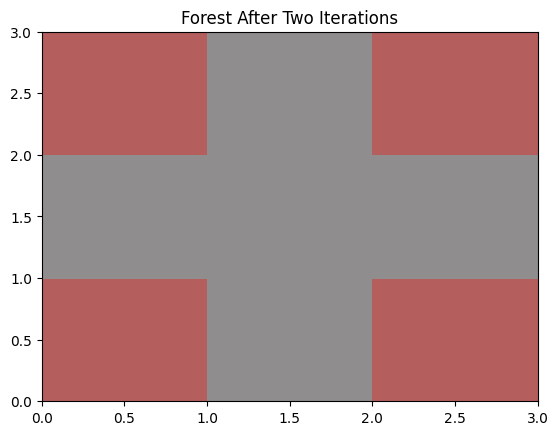

Wider Grid: Iteration 0
[[2. 2. 2. 2. 2.]
 [2. 2. 3. 2. 2.]
 [2. 2. 2. 2. 2.]]
Wider Grid: Iteration 1
[[2. 2. 3. 2. 2.]
 [2. 3. 1. 3. 2.]
 [2. 2. 3. 2. 2.]]
Wider Grid: Iteration 2
[[2. 3. 1. 3. 2.]
 [3. 1. 1. 1. 3.]
 [2. 3. 1. 3. 2.]]
Randomized P_spread:  0.9644517342411442
Randomized Forest After One Iteration:
[[2. 2. 3. 2. 2.]
 [2. 3. 1. 3. 2.]
 [2. 2. 3. 2. 2.]]
Randomized P_bare:  0.7350988332813997
Randomized P_spread:  0.4665067526922144
[[1. 1. 2. 1. 2.]
 [2. 1. 1. 2. 1.]
 [2. 1. 1. 1. 1.]]
Randomized P_ignite:  0.023531059743119087
Randomized P_bare:  0.7350988332813997
Randomized P_spread:  0.4665067526922144
[[1. 1. 2. 1. 1.]
 [2. 1. 1. 2. 1.]
 [2. 1. 1. 1. 1.]]


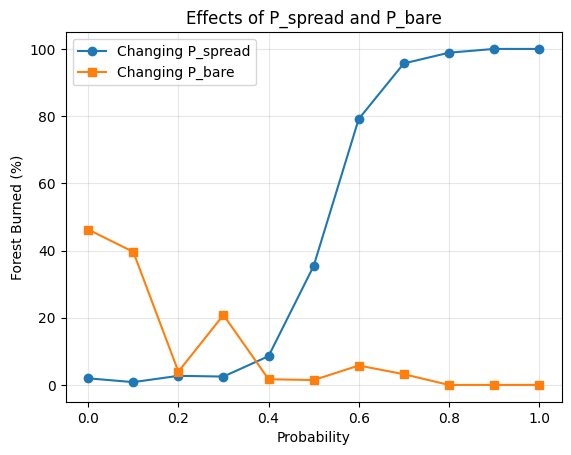

Controlled Burn Forest Before Spread:
[[2. 3. 3. 2. 2. 2. 3. 3. 2. 2.]
 [2. 2. 3. 3. 2. 3. 2. 2. 2. 3.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [2. 2. 2. 2. 2. 2. 2. 3. 2. 2.]
 [3. 2. 3. 2. 2. 3. 2. 3. 3. 3.]
 [2. 3. 3. 3. 2. 3. 2. 3. 2. 2.]
 [2. 2. 3. 2. 2. 2. 2. 2. 3. 3.]
 [2. 2. 2. 2. 3. 3. 2. 2. 2. 2.]
 [2. 2. 3. 2. 3. 2. 3. 3. 2. 2.]
 [2. 2. 3. 3. 2. 3. 3. 3. 3. 2.]]
Controlled Burn Forest After One Iteration:
P_ignite: 0.23210231777063994
P_spread: 0.31519970624102667
[[2. 1. 1. 3. 2. 2. 1. 1. 2. 3.]
 [2. 2. 1. 1. 3. 1. 3. 3. 3. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [2. 2. 2. 2. 2. 3. 3. 1. 3. 3.]
 [1. 3. 1. 3. 2. 1. 2. 1. 1. 1.]
 [2. 1. 1. 1. 2. 1. 2. 1. 3. 2.]
 [2. 2. 1. 3. 2. 3. 2. 3. 1. 1.]
 [2. 2. 2. 3. 1. 1. 3. 3. 2. 2.]
 [2. 3. 1. 3. 1. 3. 1. 1. 3. 2.]
 [2. 3. 1. 1. 2. 1. 1. 1. 1. 2.]]
Controlled Burn Forest After Two Iterations:
[[2. 1. 1. 1. 3. 2. 1. 1. 3. 1.]
 [2. 2. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [2. 3. 2. 2. 2. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 2. 1.

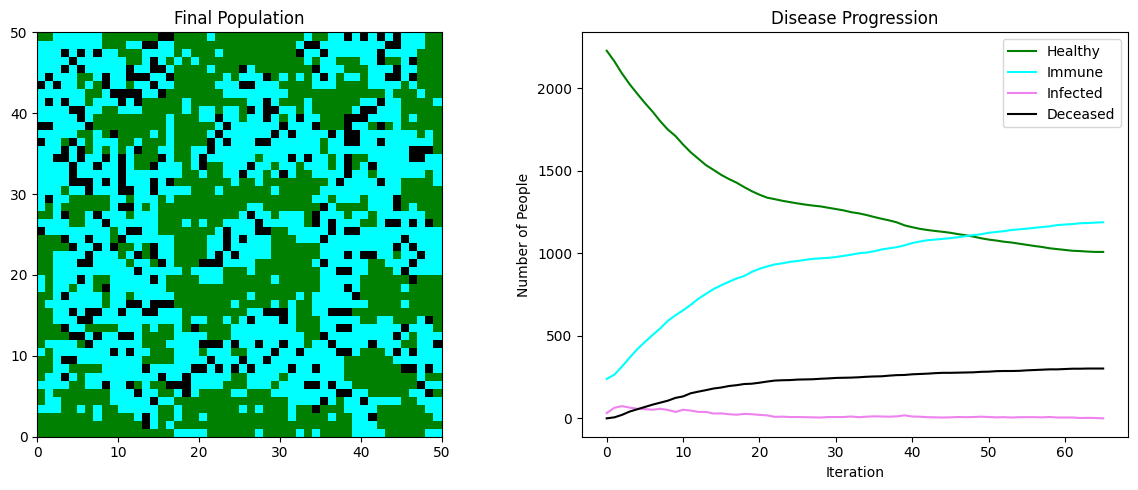

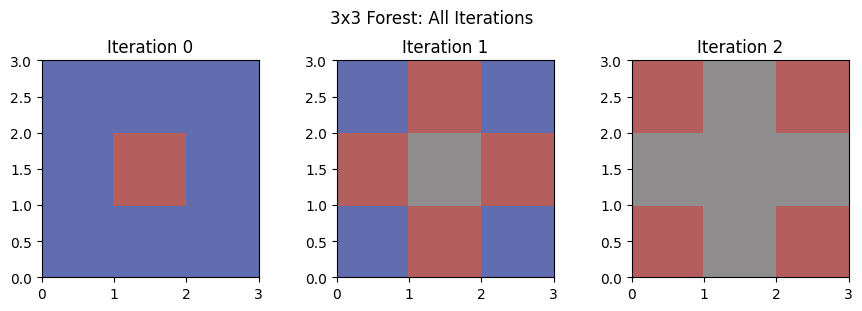

In [ ]:
# Lab 1: Spread of Forest Fires
# Keira Slocum Climate 410

# Import necessary libraries
import numpy as np  # Imports numpy for arrays and random numbers.
import matplotlib.pyplot as plt  # Imports matplotlib for plotting.
#plt.ion() # Turns on interactive mode for plotting.
from matplotlib.colors import ListedColormap  # Imports a custom color map tool.


# Defining global variables + constants
nx, ny = 3, 3  # Number of cells in x and y directions
prob_spread = 1.0  # Chance to spread to adjacent
prob_bare = 0.0  # Chance of cell to start as bare
prob_start = 0.0  # Chance of cell to start on fire

#Task 1
# Function for spreading fire one time step
def spread_fire(forest, prob_spread): 
    '''
    Given a forest grid and the probability of a fire to spread, this function determines how the fire spreads from cell to cell at each time step

    Parameters: 
    forest (np array): A 2D array representing the forest grid, where each cell can be in one of three states: 1 (barren), 2 (untouched), or 3 (burning).
    prob_spread (float): The probability that a burning cell will ignite an adjacent healthy forest

    Returns:
    new_forest (np array): A 2D array representing the updated forest grid after the final time step

    Example usage: 
    new_forest = spread_fire(forest, 0.3)
    '''
    old_forest = forest.copy()  # Saves the original grid before changes
    new_forest = forest.copy()  # Makes a new grid for burning values
    ny, nx = forest.shape  # Gets the number of rows and columns

    for i in range(nx):  # Loops through each column.
        for j in range(ny):  # Loops through each row.
            if old_forest[j, i] == 3:  # check if cell is burning

                if j > 0:  # check there's a cell above
                    if old_forest[j - 1, i] == 2:  # Checks if above is forest
                        if np.random.rand() < prob_spread:  # Rolls for spread
                            new_forest[j - 1, i] = 3  # Sets above on fire

                if j < ny - 1:  # check that there is a cell below
                    if old_forest[j + 1, i] == 2:  # Checks if below is forest
                        if np.random.rand() < prob_spread:  # random spread
                            new_forest[j + 1, i] = 3  # Sets below on fire

                if i > 0:  # Is there a cell to the left?
                    if old_forest[j, i - 1] == 2:  # is the left a forest cell?
                        if np.random.rand() < prob_spread:  # random gen spread
                            new_forest[j, i - 1] = 3  # fires left

                if i < nx - 1:  # Cell to right?
                    if old_forest[j, i + 1] == 2:  # Is cell to right the forest?
                        if np.random.rand() < prob_spread:  # random spread
                            new_forest[j, i + 1] = 3  #set on fire

                new_forest[j, i] = 1  # Changes the burning cell to barren after it has spread

    return new_forest 


# Task 1 Test 1 
# for 100% spread, 3x3 grid, no initial barren, fire in center

forest = np.zeros([ny, nx]) + 2  # Creates a 3x3 grid of healthy forest.
forest[1, 1] = 3  # Sets the center cell on fire.
forest_3x3_iterations = [forest.copy()]

#Printing the initial grid
print("Iteration 0")
print(forest)

forest = spread_fire(forest, prob_spread)  # Runs the model one time step.
forest_3x3_iterations.append(forest.copy())

#Printing grid after 1 step
print("Iteration 1") 
print(forest)  

forest = spread_fire(forest, prob_spread)  # Runs the model a second time step.
forest_3x3_iterations.append(forest.copy())

#Printing grid after 2 steps
print("Iteration 2")  
print(forest)


# Plots + Visualization
forest_cmap = ListedColormap(["#8f8d8d", "#616daf", "#b45e5e"])  # Gray, blue, red (colorblind friendly?)

fig, ax = plt.subplots(1, 1)
#plots the final forest
ax.pcolor(forest, cmap=forest_cmap, vmin=1, vmax=3)  
ax.set_title("Forest After Two Iterations")
plt.show()  # Shows the plot.

#Task 1 Test 2
# for 100% spread, 5x3 grid, no initial barren, fire in center

nx, ny = 5, 3  
prob_spread = 1.0

#create a 5x3 unburnt forest + set fire in center cell
forest = np.zeros([ny, nx]) + 2 
forest[1, 2] = 3

#Printing the initial grid
print("Wider Grid: Iteration 0")
print(forest)

forest = spread_fire(forest, prob_spread)

#printing the grid after 1 iteration
print("Wider Grid: Iteration 1")
print(forest)

forest = spread_fire(forest, prob_spread)

#printing the grid after 2 iterations
print("Wider Grid: Iteration 2")
print(forest)

#Expected Output (check results for match)
# Wider Grid: Iteration 0
#[[2. 2. 2. 2. 2.]
# [2. 2. 3. 2. 2.]
# [2. 2. 2. 2. 2.]]

#Wider Grid: Iteration 1
#[[2. 2. 3. 2. 2.]
# [2. 3. 1. 3. 2.]
# [2. 2. 3. 2. 2.]]

#Wider Grid Iteration 2
#[[2. 3. 1. 3. 2.]
# [3. 1. 1. 1. 3.]
# [2. 3. 1. 3. 2.]]

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
#Task 2: Randomized Wildire Spread

#Task 2A Part 1: run a series of simulations where you vary P_spread from 0 to 1. 

#Randomize P_spread for 0-1
nx, ny = 5, 3
forest = np.zeros([ny, nx]) + 2
P_spread = np.random.rand()
forest[1, 2] = 3  # keep fire in center cell


forest = spread_fire(forest, P_spread)

print("Randomized P_spread: ", P_spread)
print("Randomized Forest After One Iteration:")
print(forest)

#Task 2A Part 2: run a series of simulations where you vary the amount of non-forested cells from 0% to 100% using P_bare.
nx, ny = 5, 3
forest = np.zeros([ny, nx]) + 2
P_spread = np.random.rand()
forest[1,2] = 3  # keep fire in center cell 

#Adding P_Bare, let's use it to set the initial forest to have bare spots. For each cell, pick a random number. If it's lower than P_bare that cell is considered bare.
P_bare = np.random.rand()
#brute force method from lab document
for i in range(nx):
    for j in range(ny):
        # Roll our "dice" to see if we get a bare spot:
        if np.random.rand() < P_bare:
            forest[j, i] = 1 # 1 is bare

forest = spread_fire(forest, P_spread)
print("Randomized P_bare: ", P_bare)
print("Randomized P_spread: ", P_spread)
print(forest)

# Instead of center fire, use P_ignite to set several sets of cells on fire during initialization.

#P_ignite: probability that a cell is initially on fire
#Same structure as P_bare but w/ 3 instead of 1
P_ignite = np.random.rand()
for i in range(nx):
    for j in range(ny):
        if np.random.rand() < P_ignite:
            forest[j, i] = 3 #3 is burning

forest = spread_fire(forest, P_spread)
print("Randomized P_ignite: ", P_ignite)
print("Randomized P_bare: ", P_bare)
print("Randomized P_spread: ", P_spread)
print(forest)

#Task 2A plot

#Runs one complete fire
def test_fire(P_spread, P_bare):
    '''
    Runs a simulation to produce figures demonstrating the impacts of P_spread and P_bare

    Parameters:
    P_spread (float): Chance that fire spreads to a neighboring forest cell
    P_bare (float): Chance that a cell starts as bare ground

    Returns:
    percent_burned (float): Percentage of the starting forest that burned
    '''

    #Creates a 20x20 healthy forest
    test_forest = np.zeros((20, 20)) + 2

    #Adds random bare cells
    test_forest[np.random.rand(20, 20) < P_bare] = 1

    #Finds healthy cells that randomly start burning
    ignite = (np.random.rand(20, 20) < 0.01) & (test_forest == 2)

    #Sets those cells on fire
    test_forest[ignite] = 3

    #Counts the starting forest cells
    starting_forest = np.sum(test_forest != 1)

    #Runs the fire until it ends
    while np.any(test_forest == 3):
        test_forest = spread_fire(test_forest, P_spread)

    #Returns zero if there was no forest
    if starting_forest == 0:
        return 0

    #Calculates percent burned
    return 100 * (starting_forest - np.sum(test_forest == 2)) / starting_forest


#Creates probability values from 0 to 1
probabilities = np.linspace(0, 1, 11)

#Tests different spread probabilities
spread_results = [test_fire(value, 0.10) for value in probabilities]

#Tests different bare probabilities
bare_results = [test_fire(0.50, value) for value in probabilities]

#Plots both experiments
plt.plot(probabilities, spread_results, marker="o", label="Changing P_spread")
plt.plot(probabilities, bare_results, marker="s", label="Changing P_bare")

#labels
plt.xlabel("Probability")
plt.ylabel("Forest Burned (%)")
plt.title("Effects of P_spread and P_bare")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#Task 2B: Impact of controlled burns

#To see the impact of controlled burns, we can set a few cells to be burning at the start of the simulation. 
# This will allow us to see how the fire spreads from multiple points and how it affects the overall forest.

nx,ny = 10,10
forest = np.zeros([ny, nx]) + 2
P_spread = np.random.rand()

#only ignite above the controlled burn line (row 2) to see how the fire spreads from the controlled burn area.
P_ignite = np.random.rand()
for i in range(nx):
    for j in range(ny):
        if np.random.rand() < P_ignite:
            forest[j, i] = 3 #3 is burning

#Set bare specifics
forest[2,0]=1
forest[2,1]=1
forest[2,2] = 1
forest[2,3] = 1
forest[2,4] = 1
forest[2,5] = 1
forest[2,6] = 1
forest[2,7] = 1
forest[2,8]=1
forest[2,9]=1

print("Controlled Burn Forest Before Spread:")
print(forest)
forest = spread_fire(forest, P_spread)
print("Controlled Burn Forest After One Iteration:")
print("P_ignite:", P_ignite)
print("P_spread:", P_spread)
print(forest)
forest = spread_fire(forest, P_spread)
print("Controlled Burn Forest After Two Iterations:")
print(forest)

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- 
#Task 3: Zombie Infection Model
# States: 2 is healthy, 3 is sick, 1 is survivor (immune), 0 is dead
# P_fatal: Chance that 3 becomes 0 (dead) each time step
# P_bare: Initial immune (vaccinated) population - randomized

# Setting big grid because populations are large and it makes the spread effects more visible.
nx = 50
ny = 50

P_spread = 0.50
P_ignite = 0.01

#Probability of Immunity
P_bare = 0.10
# Set the probability that an infected person dies.
P_fatal = 0.25


# Create a function which finds the initial population state in one step.
def initialize_population(nx, ny, P_bare, P_ignite):
    '''
    Initializes the population grid with healthy, immune, and infected individuals based on given probabilities.

    Parameters: 
    nx (int): Number of columns in the population grid.
    ny (int): Number of rows in the population grid.
    P_bare (float): Probability that an individual is immune (vaccinated) at the start.
    P_ignite (float): Probability that an individual is infected at the start.

    Returns:
    population (array): A 2D array representing the initial population grid, 
    where each cell can be in one of four states: 0 (deceased), 1 (immune), 2 (healthy), or 3 (infected)
    '''

    # Create a grid, every person begins healthy (2)
    population = np.full((ny, nx), 2, dtype=int)

    # Generate one random number for every person
    immune_random = np.random.rand(ny, nx)

    # Identify people who receive the vaccine and begin immune
    immune_cells = immune_random < P_bare

    # Change vaccinated people to immune (1)
    population[immune_cells] = 1

    # Generate another random number for every person
    infected_random = np.random.rand(ny, nx)

    # Infect people only if they are currently healthy (if 2)
    infected_cells = (infected_random < P_ignite) & (population == 2)

    # Change initially infected people to 3
    population[infected_cells] = 3


    #IMPORTANT!!!! Make sure at least one person is infected to start. 
    # Check whether the random initialization produced no infected people.
    if np.sum(population == 3) == 0:

        # Find the center row of the grid.
        center_y = ny // 2
        # Find the center column of the grid.
        center_x = nx // 2
        # Set the center person to infected (like center fire cell)
        population[center_y, center_x] = 3
    # Return the completed population grid.
    return population

#Function for spreading infection (Mimics Spread_burn)
def spread_infection(population, P_spread, P_fatal):
    '''
    Function representing the simulation for Zombie Infection Spread

    Parameters:
    population (array): Current population grid
    P_spread (float): Chance that infection spreads to a healthy neighbor
    P_fatal (float): Chance that an infected person dies

    Returns:
    new_population (array): Updated population grid
    '''

    old_population = population.copy()  # Saves the original grid before changes
    new_population = population.copy()  # Makes a new grid for updated values
    ny, nx = population.shape  # Gets the number of rows and columns

    for i in range(nx):  # Loops through each column
        for j in range(ny):  # Loops through each row
            if old_population[j, i] == 3:  # Checks if person is infected

                if j > 0:  # Checks there is a person above
                    if old_population[j - 1, i] == 2:  # Checks if above is healthy
                        if np.random.rand() < P_spread:  # Rolls for spread
                            new_population[j - 1, i] = 3  # Infects person above

                if j < ny - 1:  # Checks there is a person below
                    if old_population[j + 1, i] == 2:  # Checks if below is healthy
                        if np.random.rand() < P_spread:  # Rolls for spread
                            new_population[j + 1, i] = 3  # Infects person below

                if i > 0:  # Checks there is a person to the left
                    if old_population[j, i - 1] == 2:  # Checks if left is healthy
                        if np.random.rand() < P_spread:  # Rolls for spread
                            new_population[j, i - 1] = 3  # Infects person to left

                if i < nx - 1:  # Checks there is a person to the right
                    if old_population[j, i + 1] == 2:  # Checks if right is healthy
                        if np.random.rand() < P_spread:  # Rolls for spread
                            new_population[j, i + 1] = 3  # Infects person to right

                if np.random.rand() < P_fatal:  # Rolls for death
                    new_population[j, i] = 0  # Changes infected person to dead
                else:  # If infected person survives
                    new_population[j, i] = 1  # Changes surviving person to immune

    return new_population  # Returns the updated population grid

# Initialize the population before the simulation begins.
population = initialize_population(nx, ny, P_bare, P_ignite)
# Create lists to record the number of ppl in each state
healthy_history = [np.sum(population == 2)]
immune_history = [np.sum(population == 1)]
infected_history = [np.sum(population == 3)]
deceased_history = [np.sum(population == 0)]
# Max iterations because my infinite loop was bad for my computer :(
maximum_iterations = 500
# Begin counting iterations at zero
iteration = 0

# Continue while infected people remain and the maximum has not been reached.
while np.any(population == 3) and iteration < maximum_iterations:

    #Go forward one iteration
    population = spread_infection(population, P_spread, P_fatal)
    #Iterate (to count with each and prevent from exceeding 500 and continuing forever)
    iteration += 1

    # Record the number of healthy people.
    healthy_history.append(np.sum(population == 2))
    # Record the number of immune people.
    immune_history.append(np.sum(population == 1))
    # Record the number of infected people.
    infected_history.append(np.sum(population == 3))
    # Record the number of deceased people.
    deceased_history.append(np.sum(population == 0))


#Print the number of iterations completed
print("Number of iterations:", iteration)
#Print the final numbers of each condition
print("Healthy:", healthy_history[-1])
print("Immune:", immune_history[-1])
print("Infected:", infected_history[-1])
print("Deceased:", deceased_history[-1])


# Assign a color to each population state.
zombie_cmap = ListedColormap([
    "black",       #0 = dead people
    "aqua",        #1 = immune people
    "green",       #2 = healthy people (Not red and green bc Jeremy is colorblind)
    "violet"          #3 = infected people.
])

# Create two plots next to each other.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Display the final population grid
axes[0].pcolor(population, cmap=zombie_cmap, vmin=0, vmax=3)
axes[0].set_title("Final Population")
# Cells are squares
axes[0].set_aspect("equal")
#Plotting:
#number of healthy people over time
axes[1].plot(healthy_history, color="green", label="Healthy")
#number of immune people over time
axes[1].plot(immune_history, color="aqua", label="Immune")
#infected people over time
axes[1].plot(infected_history, color="violet", label="Infected")
#deceased people over time
axes[1].plot(deceased_history, color="black", label="Deceased")

# Labels, Title, Legend
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Number of People")
axes[1].set_title("Disease Progression")
axes[1].legend()

plt.tight_layout()
plt.show()

# Task 1: Display every iteration of the original 3x3 forest
fig, axes = plt.subplots(1, len(forest_3x3_iterations), figsize=(9, 3))
for iteration, (ax, iteration_forest) in enumerate(zip(axes, forest_3x3_iterations)):
    ax.pcolor(iteration_forest, cmap=forest_cmap, vmin=1, vmax=3)
    ax.set_title(f"Iteration {iteration}")
    ax.set_aspect("equal")

fig.suptitle("3x3 Forest: All Iterations")
plt.tight_layout()
plt.show()